# PZ data challenge: task set 3 within and across simulations, against a baseline

How well do the task set 3 (spec + COSMOS) models trained on Flagship do on Flagship, and on Cardinal, a simulation they never saw, and how does a new run compare with a baseline? Four evaluations: Y1 and Y10, each tested on

- **Flagship → Flagship**: the held-out 20% of the Flagship training file (`train_test_split` with `VAL_FRAC` and `SEED`, as in the task-set notebook; the model was trained on the other 80%), and
- **Flagship → Cardinal**: the same 20% split of the Cardinal training file.

Two runs are compared on the same held-out objects:

- **the baseline** (`BASELINE_OUT_DIR`, named `BASELINE_LABEL`), by default the K-fold ensemble of `znn.build_model` trained from scratch: a base model trained on the whole fit set, then 10 members fine-tuned from it on their K-fold cuts (the stem frozen). Its p(z) is a Gaussian with the mean and std of the members' predictions over `N_SAMPLES` noise draws of the photometry;
- **the run** (`OUT_DIR`, named `NEW_LABEL`), by default a moment network (Jeffrey & Wandelt 2020, arXiv:2011.05991) from scratch: a model F trained once on the whole fit set, then a second instance G of the same architecture trained on F's squared residuals with F fixed (`znn.train_variance_model`), so G predicts the variance of F's prediction. Its p(z) is the Gaussian in log(1 + z) with F's mean and G's variance (`znn.moment_predict_resampled`), on the photometry as given: G's variance already includes the photometric noise of the observed data, so drawing noise on top would count it twice.

Each is set by its pre-training and method (`BASELINE` and `RUN`), and its directory follows from them, as the task-set notebooks name it.

The notebook is self-contained: if a run's trained models (the subtask 2 `.pkl` model files) are not in its directory, it trains them on the same split (and, for the K-fold ensemble, with the same settings as `pz_challenge_taskset3_e2e.ipynb`) and saves them there; if they are, it uses them. The p(z)s are predicted here with the current `znn` code, and scored with the challenge metrics and on their stacked n(z).

The held-out predictions of each run are cached in `<its OUT_DIR>_predictions`, shared with `pz_challenge_results.ipynb` (the mock evaluation of all task sets, for submissions). Delete a cache to recompute, e.g. after changing how `znn` builds the p(z). Figures (`.pdf`) and LaTeX tables (`.tex`) are saved to `PLOT_DIR`, prefixed so they never overwrite those of `pz_challenge_results.ipynb`.

Run this from the repo root with the `qp` conda env as the kernel.

## Configuration

In [1]:
import znn  # run from the repo root so this picks up the local source

# the models: task set TASKSET trained on TRAIN_SIM at each depth, tested on the held-out split of each of TEST_SIMS
TASKSET = 3
TRAIN_SIM = "flagship"
TEST_SIMS = ["flagship", "cardinal"]
SCENARIOS = ["1yr", "10yr"]

DATA_DIR = "../pz_data_challenge/scripts/public"  # as in the task-set notebooks
# The two runs compared, each as (label, pretraining, method), and trained below if its model files are not in its
# directory. pretraining: "popcosmos" (the pre-training shipped with znn, only the starting point of the weights) or
# None (from scratch). method:
#   "kfold": a K-fold ensemble, as in pz_challenge_taskset3_e2e.ipynb (with FROM_BASE, members fine-tuned from a base
#            model with its stem frozen); p(z) over N_SAMPLES noise draws of the photometry
#   "moment": a moment network, a model F and a second network G learning F's squared residuals with F fixed; p(z)
#             on the photometry as given
BASELINE = ("scratch, K-fold ensemble", None, "kfold")
RUN = ("scratch, moment network", None, "moment")
# FROM_BASE (K-fold runs): train a base model, then fine-tune a copy of it per member (True), or train every member
# in full (False)
FROM_BASE = True


def run_dir(pretraining, method):
    # The directory of a run's model files, as the task-set notebooks name it: "build_model_res_se_log1pz" (the
    # name znn.build_model had when it was added, which keeps its runs apart from those of the old model), then the
    # method version: "kfold" (every member on its own K-fold cut), plus "_frombase" with FROM_BASE, or "moment"
    version = "kfold" + ("_frombase" if FROM_BASE else "") if method == "kfold" else method
    prefix = "outputs/znn" if pretraining is None else f"outputs/znn_pretrained_{pretraining}"
    return f"{prefix}_build_model_res_se_log1pz_{version}"


BASELINE_LABEL, NEW_LABEL = BASELINE[0], RUN[0]
BASELINE_OUT_DIR, OUT_DIR = run_dir(*BASELINE[1:]), run_dir(*RUN[1:])
PLOT_DIR = "plots"  # figures and LaTeX tables are saved here, prefixed with the run name and the evaluation

# the held-out split: must match the task-set notebook
VAL_FRAC = 0.2
SEED = 42
# prediction of the K-fold runs: photometric noise draws per object (converged by 50 on Cardinal Y1) and their seed
N_SAMPLES = 50
NOISE_SEED = 42
# training, only of a run whose model files are missing: as in the task-set notebook
N_MEMBERS = 10 if FROM_BASE else 5  # ensemble members, and K-fold folds
EPOCHS = 100  # max epochs per member, of the base model with FROM_BASE, or of F and of G (early stopping usually ends sooner)
FINETUNE_EPOCHS = 10  # FROM_BASE: epochs of each member's fine-tuning (no early stopping)
FINETUNE_LR = 3e-4  # FROM_BASE: constant fine-tuning learning rate

I0000 00:00:1793705523.203778 2256419 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.


In [2]:
import itertools
import os
import re

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import qp
from qp.metrics.pit import PIT
from sklearn.model_selection import train_test_split

os.makedirs(PLOT_DIR, exist_ok=True)

# the two runs, baseline first: label -> its directory, and label -> its method
RUNS = {BASELINE_LABEL: BASELINE_OUT_DIR, NEW_LABEL: OUT_DIR}
METHODS = {BASELINE_LABEL: BASELINE[2], NEW_LABEL: RUN[2]}
assert len(RUNS) == 2, "the two runs need different labels"
assert BASELINE_OUT_DIR != OUT_DIR, "the two runs are the same run"
# one colour per task set, as in pz_challenge_results.ipynb; its colour map is used for 2D densities. The baseline
# is grey
TASKSET_CMAPS = {1: "Blues", 2: "Greens", 3: "Oranges", 4: "Purples"}
COLORS = {t: plt.get_cmap(cmap)(0.7) for t, cmap in TASKSET_CMAPS.items()}
RUN_COLORS = {BASELINE_LABEL: "0.35", NEW_LABEL: COLORS[TASKSET]}
RUN_CMAPS = {BASELINE_LABEL: "Greys", NEW_LABEL: TASKSET_CMAPS[TASKSET]}
TRAIN_COLOR = "0.6"
# how sims and depths are written in plots and tables
SIM_LABELS = {"cardinal": "Cardinal", "flagship": "Flagship"}
DEPTH_LABELS = {"1yr": "Y1", "10yr": "Y10"}
INDEX_LABELS = {"test": "Tested on", "scenario": "Depth", "model": "Model"}
# prefix of the saved figures and tables
PREFIX = f"{os.path.basename(OUT_DIR)}_vs_{os.path.basename(BASELINE_OUT_DIR)}_taskset{TASKSET}_{TRAIN_SIM}_transfer"


def transfer_label(test_sim):
    # training -> test simulation
    return f"{SIM_LABELS[TRAIN_SIM]} → {SIM_LABELS[test_sim]}"


def save(fig, name):
    fig.savefig(os.path.join(PLOT_DIR, f"{PREFIX}_{name}.pdf"), bbox_inches="tight")


def save_latex(df, name, columns, caption):
    # Write df as a booktabs LaTeX table (columns: {df column: LaTeX header}) to PLOT_DIR and print it. Values of
    # 10 or more (the Anderson-Darling statistic) get one decimal, the rest four.
    df = df[list(columns)].rename(columns=columns, index=SIM_LABELS | DEPTH_LABELS)
    tex = df.rename_axis([INDEX_LABELS[n] for n in df.index.names]).to_latex(
        float_format=lambda v: f"{v:.1f}" if abs(v) >= 10 else f"{v:.4f}", multirow=True, caption=caption,
        label=f"tab:{name}", position="htbp",
    )
    # a rule between groups of the first index level only
    tex = re.sub(r"^(?:\\cline\{\d+-\d+\} ?)+\n", lambda m: "\\midrule\n" if "\\cline{1-" in m[0] else "", tex, flags=re.M)
    tex = tex.replace("\\midrule\n\\bottomrule", "\\bottomrule")
    with open(os.path.join(PLOT_DIR, f"{PREFIX}_{name}.tex"), "w") as f:
        f.write(tex)
    print(tex)


def path(kind, taskset, sim, scenario, out_dir=OUT_DIR):
    if kind in ("training", "test"):
        return os.path.join(DATA_DIR, f"pz_challenge_taskset_{taskset}_{sim}_{kind}_{scenario}.hdf5")
    return os.path.join(out_dir, f"pz_challenge_taskset_{taskset}_{sim}_{kind}_{scenario}.pkl")


def cache_stem(out_dir, taskset, sim, scenario, test_sim):
    # the cached held-out predictions of the model of the run in out_dir trained on sim, on test_sim's held-out split
    on = "" if test_sim == sim else f"_on_{test_sim}"
    return os.path.join(f"{out_dir}_predictions", f"taskset_{taskset}_{sim}{on}_{scenario}_pz")

## Reference redshifts

These are the same labels as in the task-set notebooks: `redshift` for spectroscopically selected objects and `redshift_manyband` for COSMOS-only objects, so the scores include the label noise of the COSMOS-only objects, on both simulations.


In [3]:
SPEC_SURVEYS = ["DEEP2_LSST", "DESI_BGS", "DESI_ELG_LOP", "DESI_LRG", "VVDSf02", "zCOSMOS"]


def reference_redshifts(train):
    # Reference redshift per training object.
    z_spec = train["redshift"].to_numpy()
    if "COSMOS" not in train:  # task sets 1 and 2
        return z_spec
    is_spec = train[[c for c in SPEC_SURVEYS if c in train]].astype(bool).any(axis=1).to_numpy()
    is_cosmos_only = train["COSMOS"].astype(bool).to_numpy() & ~is_spec
    z_ref = np.where(is_cosmos_only, train["redshift_manyband"].to_numpy(), z_spec)
    assert np.isfinite(z_ref).all()
    return z_ref


## Train the runs (only if needed)

For each run and depth whose model file is not in the run's directory, the run is trained on the Flagship training file minus the held-out split, on the photometry as given, and saved there.

- **K-fold ensemble** (`"kfold"`), as in `pz_challenge_taskset3_e2e.ipynb`: every member on its own K-fold cut (`znn.train_from_catalog`). The photometric errors only enter the prediction (`N_SAMPLES` draws). With `FROM_BASE`, a base model is first trained on the whole fit set (a random `VAL_FRAC` of it held out for early stopping), from scratch or from the pre-trained weights, every layer trainable, then each of the `N_MEMBERS` members is fine-tuned from it on its own K-fold cut with the base model's stem (its first conv and batch-norm) frozen, the same in every member.
- **Moment network** (`"moment"`): F is trained once on the whole fit set (`znn.train_model`, a random `VAL_FRAC` held out for early stopping), from scratch or from the pre-trained weights; then G, a new instance of the same architecture, is trained from scratch on F's squared residuals on the same objects, with F fixed (`znn.train_variance_model`). Both are saved in one model file, as `[(F, 0, 1), (G, 0, s²)]`.

Any cached held-out predictions of a run and depth trained here are deleted, since they came from an older model. Depths whose model file exists are not retrained; delete the file to retrain.

found outputs/znn_build_model_res_se_log1pz_kfold_frombase/pz_challenge_taskset_3_flagship_pz_model_1yr.pkl
found outputs/znn_build_model_res_se_log1pz_kfold_frombase/pz_challenge_taskset_3_flagship_pz_model_10yr.pkl

========== training scratch, moment network: task set 3 flagship 1yr ==========


I0000 00:00:1793705585.407217 2256419 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 79189 MB memory:  -> device: 0, name: NVIDIA A100-SXM4-80GB, pci bus id: 0000:03:00.0, compute capability: 8.0
I0000 00:00:1793705585.411235 2256419 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 79189 MB memory:  -> device: 1, name: NVIDIA A100-SXM4-80GB, pci bus id: 0000:41:00.0, compute capability: 8.0
I0000 00:00:1793705585.415168 2256419 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:2 with 79189 MB memory:  -> device: 2, name: NVIDIA A100-SXM4-80GB, pci bus id: 0000:82:00.0, compute capability: 8.0
I0000 00:00:1793705585.418898 2256419 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:3 with 79189 MB memory:  -> device: 3, name: NVIDIA A100-SXM4-80GB, pci bus id: 0000:c1:00.0, compute capability: 8.0


Epoch 1/100


I0000 00:00:1793705594.435696 2256889 service.cc:153] XLA service 0x7ef93c062580 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1793705594.435731 2256889 service.cc:161]   StreamExecutor [0]: NVIDIA A100-SXM4-80GB, Compute Capability 8.0 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793705594.435741 2256889 service.cc:161]   StreamExecutor [1]: NVIDIA A100-SXM4-80GB, Compute Capability 8.0 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793705594.435745 2256889 service.cc:161]   StreamExecutor [2]: NVIDIA A100-SXM4-80GB, Compute Capability 8.0 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793705594.435748 2256889 service.cc:161]   StreamExecutor [3]: NVIDIA A100-SXM4-80GB, Compute Capability 8.0 (Driver: 13.0.0; Runtime: 12.9.0; Toolkit: 12.5.0; DNN: 9.27.0)
I0000 00:00:1793705594.610180 2256889 dump_mlir_util.cc:269] disabling MLIR crash repro

250/250 - 42s - 166ms/step - loss: 0.3150 - val_loss: 0.7726 - learning_rate: 0.0010
Epoch 2/100
250/250 - 1s - 5ms/step - loss: 0.2494 - val_loss: 0.3590 - learning_rate: 0.0010
Epoch 3/100
250/250 - 1s - 5ms/step - loss: 0.2390 - val_loss: 0.2213 - learning_rate: 0.0010
Epoch 4/100
250/250 - 1s - 5ms/step - loss: 0.2327 - val_loss: 0.2359 - learning_rate: 0.0010
Epoch 5/100
250/250 - 1s - 5ms/step - loss: 0.2285 - val_loss: 0.2258 - learning_rate: 0.0010
Epoch 6/100

Epoch 6: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
250/250 - 1s - 5ms/step - loss: 0.2283 - val_loss: 0.2361 - learning_rate: 0.0010
Epoch 7/100
250/250 - 1s - 5ms/step - loss: 0.2135 - val_loss: 0.2072 - learning_rate: 5.0000e-04
Epoch 8/100
250/250 - 1s - 5ms/step - loss: 0.2095 - val_loss: 0.2107 - learning_rate: 5.0000e-04
Epoch 9/100
250/250 - 1s - 5ms/step - loss: 0.2082 - val_loss: 0.2301 - learning_rate: 5.0000e-04
Epoch 10/100

Epoch 10: ReduceLROnPlateau reducing learning rate to 0.0002

I0000 00:00:1793705658.517701 2256888 dot_search_space.cc:240] All configs were filtered out because none of them sufficiently match the hints. Maybe the hints set does not contain a good representative set of valid configs? Working around this by using the full hints set instead.


Epoch 1/100


I0000 00:00:1793705669.639661 2256889 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_50627__.107


250/250 - 17s - 68ms/step - loss: 0.6548 - val_loss: 0.9572 - learning_rate: 0.0010
Epoch 2/100
250/250 - 1s - 5ms/step - loss: 0.6316 - val_loss: 0.9208 - learning_rate: 0.0010
Epoch 3/100
250/250 - 1s - 5ms/step - loss: 0.6282 - val_loss: 0.9089 - learning_rate: 0.0010
Epoch 4/100
250/250 - 1s - 5ms/step - loss: 0.6278 - val_loss: 0.9120 - learning_rate: 0.0010
Epoch 5/100
250/250 - 1s - 5ms/step - loss: 0.6259 - val_loss: 0.9068 - learning_rate: 0.0010
Epoch 6/100
250/250 - 1s - 5ms/step - loss: 0.6258 - val_loss: 0.9158 - learning_rate: 0.0010
Epoch 7/100
250/250 - 1s - 5ms/step - loss: 0.6240 - val_loss: 0.9061 - learning_rate: 0.0010
Epoch 8/100
250/250 - 1s - 5ms/step - loss: 0.6243 - val_loss: 0.9036 - learning_rate: 0.0010
Epoch 9/100
250/250 - 1s - 5ms/step - loss: 0.6248 - val_loss: 0.9179 - learning_rate: 0.0010
Epoch 10/100
250/250 - 1s - 5ms/step - loss: 0.6239 - val_loss: 0.9062 - learning_rate: 0.0010
Epoch 11/100

Epoch 11: ReduceLROnPlateau reducing learning rate to 0

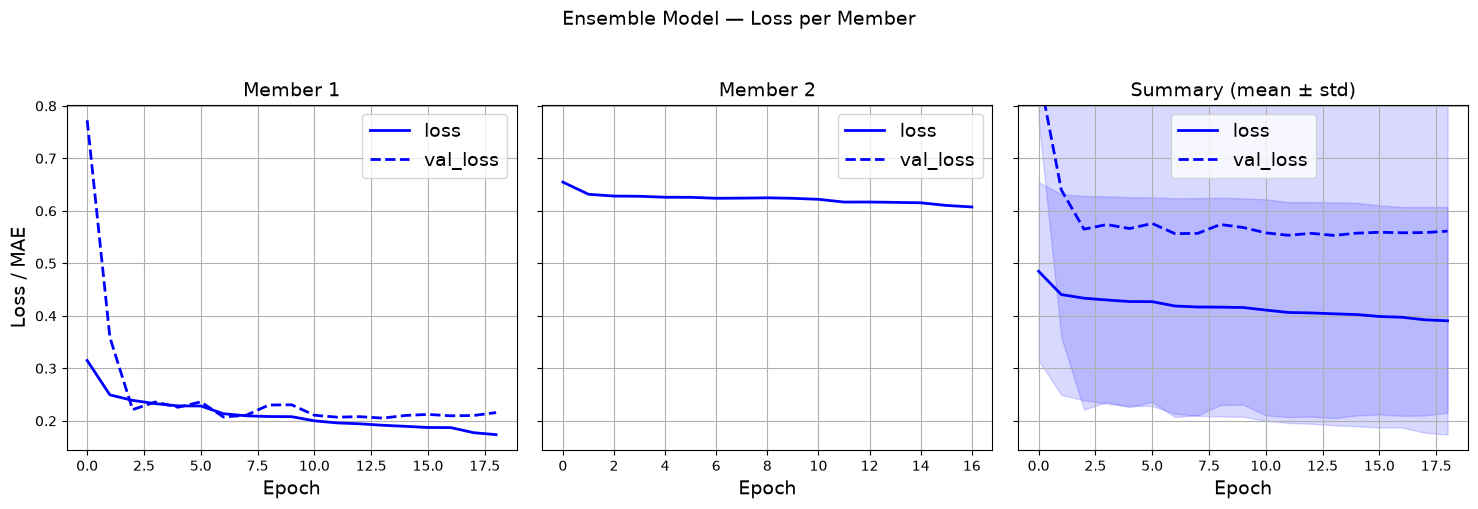

saved outputs/znn_build_model_res_se_log1pz_moment/pz_challenge_taskset_3_flagship_pz_model_1yr.pkl

========== training scratch, moment network: task set 3 flagship 10yr ==========
Epoch 1/100


I0000 00:00:1793705709.192942 2256885 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_84376__.107


250/250 - 17s - 66ms/step - loss: 0.2116 - val_loss: 0.6489 - learning_rate: 0.0010
Epoch 2/100
250/250 - 1s - 5ms/step - loss: 0.1659 - val_loss: 0.1537 - learning_rate: 0.0010
Epoch 3/100
250/250 - 1s - 5ms/step - loss: 0.1573 - val_loss: 0.1587 - learning_rate: 0.0010
Epoch 4/100
250/250 - 1s - 5ms/step - loss: 0.1556 - val_loss: 0.2573 - learning_rate: 0.0010
Epoch 5/100
250/250 - 1s - 5ms/step - loss: 0.1522 - val_loss: 0.1363 - learning_rate: 0.0010
Epoch 6/100
250/250 - 1s - 5ms/step - loss: 0.1506 - val_loss: 0.1336 - learning_rate: 0.0010
Epoch 7/100
250/250 - 1s - 5ms/step - loss: 0.1477 - val_loss: 0.1248 - learning_rate: 0.0010
Epoch 8/100
250/250 - 1s - 5ms/step - loss: 0.1485 - val_loss: 0.1332 - learning_rate: 0.0010
Epoch 9/100
250/250 - 1s - 5ms/step - loss: 0.1454 - val_loss: 0.1479 - learning_rate: 0.0010
Epoch 10/100

Epoch 10: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
250/250 - 1s - 5ms/step - loss: 0.1454 - val_loss: 0.1309 - learning_rate

I0000 00:00:1793705742.948796 2256887 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_114210__.107


250/250 - 17s - 67ms/step - loss: 0.7267 - val_loss: 0.7169 - learning_rate: 0.0010
Epoch 2/100
250/250 - 1s - 5ms/step - loss: 0.7014 - val_loss: 0.7147 - learning_rate: 0.0010
Epoch 3/100
250/250 - 1s - 5ms/step - loss: 0.7003 - val_loss: 0.7156 - learning_rate: 0.0010
Epoch 4/100
250/250 - 1s - 5ms/step - loss: 0.7003 - val_loss: 0.7090 - learning_rate: 0.0010
Epoch 5/100
250/250 - 1s - 5ms/step - loss: 0.6997 - val_loss: 0.7092 - learning_rate: 0.0010
Epoch 6/100
250/250 - 1s - 5ms/step - loss: 0.6984 - val_loss: 0.7116 - learning_rate: 0.0010
Epoch 7/100

Epoch 7: ReduceLROnPlateau reducing learning rate to 0.0005000000237487257.
250/250 - 1s - 5ms/step - loss: 0.6978 - val_loss: 0.7130 - learning_rate: 0.0010
Epoch 8/100
250/250 - 1s - 5ms/step - loss: 0.6973 - val_loss: 0.7095 - learning_rate: 5.0000e-04
Epoch 9/100
250/250 - 1s - 5ms/step - loss: 0.6970 - val_loss: 0.7089 - learning_rate: 5.0000e-04
Epoch 10/100
250/250 - 1s - 5ms/step - loss: 0.6957 - val_loss: 0.7089 - learni

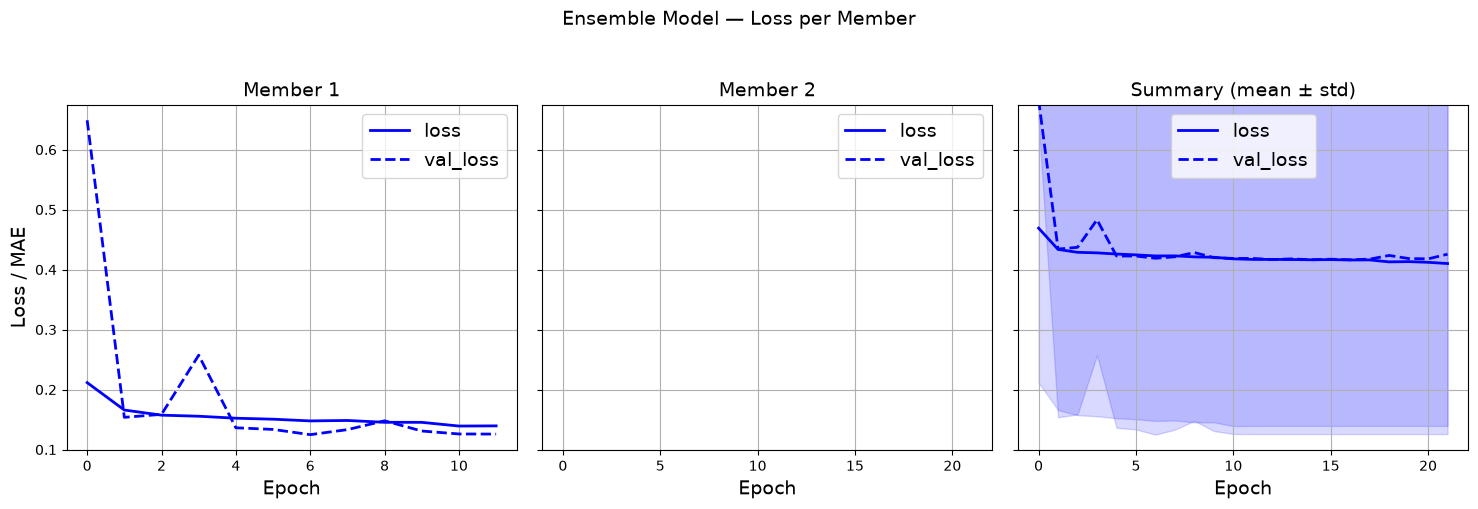

saved outputs/znn_build_model_res_se_log1pz_moment/pz_challenge_taskset_3_flagship_pz_model_10yr.pkl


In [4]:
from rail.utils.path_utils import find_rail_file

# Filter curves shipped with RAIL; the challenge's catalogs.yaml ("cardinal_roman_rubin") maps the catalogue columns
# to these DC2LSST_* and roman_* filters. As in the task-set notebook
FILTER_DIR = find_rail_file("examples_data/estimation_data/data/FILTER")
# band -> (catalogue magnitude column, filter curve file), ordered by wavelength
BANDS = {
    "u": ("mag_u_lsst", f"{FILTER_DIR}/DC2LSST_u.res"),
    "g": ("mag_g_lsst", f"{FILTER_DIR}/DC2LSST_g.res"),
    "r": ("mag_r_lsst", f"{FILTER_DIR}/DC2LSST_r.res"),
    "i": ("mag_i_lsst", f"{FILTER_DIR}/DC2LSST_i.res"),
    "z": ("mag_z_lsst", f"{FILTER_DIR}/DC2LSST_z.res"),
    "y": ("mag_y_lsst", f"{FILTER_DIR}/DC2LSST_y.res"),
    "Y": ("mag_Y_roman", f"{FILTER_DIR}/roman_Y106.res"),
    "J": ("mag_J_roman", f"{FILTER_DIR}/roman_J129.res"),
    "H": ("mag_H_roman", f"{FILTER_DIR}/roman_H158.res"),
}
REF_BAND = "i"  # magnitudes are normalized by this band
FEATURE_CONFIG = znn.DEFAULT_FEATURE_CONFIG

for (label, pretraining, method), out_dir in [(BASELINE, BASELINE_OUT_DIR), (RUN, OUT_DIR)]:
    for scenario in SCENARIOS:
        model_file = path("pz_model", TASKSET, TRAIN_SIM, scenario, out_dir)
        if os.path.exists(model_file):
            print("found", model_file)
            continue
        print(f"\n========== training {label}: task set {TASKSET} {TRAIN_SIM} {scenario} ==========")
        train = znn.read_catalog(path("training", TASKSET, TRAIN_SIM, scenario))
        z_ref = reference_redshifts(train)
        # the held-out split is left out of training: it is what the runs are scored on
        idx_fit, _ = train_test_split(np.arange(len(train)), test_size=VAL_FRAC, random_state=SEED)
        if method == "kfold":
            trained_models, histories, base_history = znn.train_from_catalog(
                znn.build_model, train.iloc[idx_fit], z_ref[idx_fit], BANDS, REF_BAND, FEATURE_CONFIG,
                N_MEMBERS=N_MEMBERS, from_base=FROM_BASE, EPOCHS=EPOCHS,
                FINETUNE_EPOCHS=FINETUNE_EPOCHS, FINETUNE_LR=FINETUNE_LR, random_state=SEED, pretraining=pretraining,
            )
            # the loss is in the standardised log(1 + z) of the target
            if base_history is not None:
                znn.plot_ensemble_losses([base_history], ylim=None)
            znn.plot_ensemble_losses(histories, ylim=None)
        else:  # "moment"
            X, _ = znn.catalog_to_XY(train.iloc[idx_fit], BANDS, REF_BAND, FEATURE_CONFIG)
            mean_member, mean_history = znn.train_model(
                znn.build_model, X, z_ref[idx_fit], VAL_FRAC=VAL_FRAC, EPOCHS=EPOCHS, random_state=SEED,
                pretraining=pretraining,
            )
            trained_models, var_history = znn.train_variance_model(
                znn.build_model, X, z_ref[idx_fit], mean_member, VAL_FRAC=VAL_FRAC, EPOCHS=EPOCHS, random_state=SEED
            )
            # the losses of F and of G, both in the standardised log(1 + z) of F (G's in its square)
            znn.plot_ensemble_losses([mean_history, var_history], ylim=None)
        plt.show()
        os.makedirs(out_dir, exist_ok=True)
        znn.save_ensemble_file(model_file, trained_models, BANDS, REF_BAND, FEATURE_CONFIG)
        print("saved", model_file)

        # held-out predictions cached from an earlier model of this run and depth are stale now
        for test_sim in TEST_SIMS:
            for ext in ("npz", "hdf5"):
                if os.path.exists(stale := f"{cache_stem(out_dir, TASKSET, TRAIN_SIM, scenario, test_sim)}.{ext}"):
                    os.remove(stale)
                    print("removed stale", stale)

# Held-out scores

Each model is run on the held-out split of Flagship and of Cardinal. Cardinal has the same task set 3 selection and bands as Flagship but a different simulated galaxy population, so Flagship → Cardinal measures how well the model carries over to galaxies unlike the ones it was trained on. Cardinal's test file has no redshifts, so its training file is used; its held-out split is the same 20k objects a Cardinal-trained model is scored on in the task-set notebook.

The K-fold runs are predicted over `N_SAMPLES` noise draws of the photometry, the moment networks on the photometry as given. Both runs use the same held-out split (`VAL_FRAC`, `SEED`), so they are scored on the same objects; this is checked.

In [5]:
def heldout_predictions(out_dir, method, taskset, sim, scenario, test_sim=None):
    # The model of the run in out_dir trained on sim with method, run on the held-out split of test_sim's training
    # file (default: sim's own). Returns the held-out reference z, i-mag, zmode, the p(z) mean and std, and the p(z)
    # (a qp ensemble) under "pz". Cached in <out_dir>_predictions: the arrays in <stem>.npz, the p(z) in <stem>.hdf5.
    test_sim = test_sim or sim
    stem = cache_stem(out_dir, taskset, sim, scenario, test_sim)
    if os.path.exists(f"{stem}.npz") and os.path.exists(f"{stem}.hdf5"):
        return dict(np.load(f"{stem}.npz")) | {"pz": qp.read(f"{stem}.hdf5")}

    model_file = path("pz_model", taskset, sim, scenario, out_dir)
    assert os.path.exists(model_file), f"no cached predictions ({stem}) or model file ({model_file})"
    train = znn.read_catalog(path("training", taskset, test_sim, scenario))
    z_ref = reference_redshifts(train)
    _, idx_val = train_test_split(np.arange(len(train)), test_size=VAL_FRAC, random_state=SEED)
    val = train.iloc[idx_val]

    trained_models, features = znn.load_ensemble_file(model_file)
    if method == "kfold":
        errors = {col: f"{col}_err" for col, _ in features["bands"].values()}
        pz = znn.ensemble_predict_resampled(
            trained_models, val, **features, errors=errors, n_samples=N_SAMPLES, rng=np.random.default_rng(NOISE_SEED)
        )
    else:  # "moment": one pass on the photometry as given (no errors to draw from)
        pz = znn.moment_predict_resampled(trained_models, val, {}, 1, np.random.default_rng(NOISE_SEED), **features)
    out = {
        "z_ref": z_ref[idx_val],
        "mag_i": val["mag_i_lsst"].to_numpy(),
        "zmode": np.squeeze(pz.ancil["zmode"]),
        "mean": np.squeeze(pz.mean()),
        "std": np.squeeze(pz.std()),
    }
    os.makedirs(os.path.dirname(stem), exist_ok=True)
    np.savez(f"{stem}.npz", **out)
    pz.write_to(f"{stem}.hdf5")
    return out | {"pz": pz}


# the evaluations, keyed by (test sim, depth); the predictions by (run, test sim, depth)
EVALS = list(itertools.product(TEST_SIMS, SCENARIOS))
heldout = {}
for model, out_dir in RUNS.items():
    for test_sim, scenario in EVALS:
        print(f"held-out predictions, {model}:", transfer_label(test_sim), DEPTH_LABELS[scenario])
        heldout[(model, test_sim, scenario)] = heldout_predictions(
            out_dir, METHODS[model], TASKSET, TRAIN_SIM, scenario, test_sim=test_sim
        )
for c in EVALS:
    assert np.array_equal(heldout[(BASELINE_LABEL, *c)]["z_ref"], heldout[(NEW_LABEL, *c)]["z_ref"]), (
        f"{c}: the two runs were scored on different held-out objects"
    )

held-out predictions, scratch, K-fold ensemble: Flagship → Flagship Y1
held-out predictions, scratch, K-fold ensemble: Flagship → Flagship Y10
held-out predictions, scratch, K-fold ensemble: Flagship → Cardinal Y1
held-out predictions, scratch, K-fold ensemble: Flagship → Cardinal Y10
held-out predictions, scratch, moment network: Flagship → Flagship Y1


/global/homes/j/jaimerz/envs/pzdc/lib/python3.12/site-packages/scipy/stats/_distn_infrastructure.py:1472: RuntimeWarning: invalid value encountered in sqrt
  res = sqrt(self.stats(*args, **kwds))


held-out predictions, scratch, moment network: Flagship → Flagship Y10
held-out predictions, scratch, moment network: Flagship → Cardinal Y1
held-out predictions, scratch, moment network: Flagship → Cardinal Y10


In [6]:
def challenge_metrics(z_ref, zmode, pz):
    # The challenge's seven scored metrics, computed as in the task-set notebooks.
    dz = (zmode - z_ref) / (1 + z_ref)
    bias, _, scatter, _, abs_outlier_rate = znn.get_biweight_mean_sigma_outlier(dz)
    pit = PIT(pz, z_ref)
    return {
        "mean": bias,
        "std": scatter,
        "abs_outlier_rate": abs_outlier_rate,
        "ks": pit.evaluate_PIT_KS().statistic,
        "CvM": pit.evaluate_PIT_CvM().statistic,
        "ksamp": pit.evaluate_PIT_anderson_ksamp().statistic,
        # qp derives this from a spline fit to the PIT quantiles and it breaks down (negative or huge values)
        # when PIT piles up at 0 or 1; the challenge evaluator uses the same call, so it is what gets scored
        "outlier": pit.evaluate_PIT_outlier_rate(),
    }, pit.pit_samps


results, pits = {}, {}
for c, h in heldout.items():
    results[c], pits[c] = challenge_metrics(h["z_ref"], h["zmode"], h["pz"])

# ks is shown on the PIT histograms; ks and CvM are graded in pz_challenge_results.ipynb
METRICS = ["mean", "std", "abs_outlier_rate", "ksamp", "outlier"]
table = pd.DataFrame(results).T[METRICS]
table.index.names = ["model", "test", "scenario"]

# side by side: each metric for the baseline, then the run
comparison = pd.concat({model: table.loc[model] for model in RUNS}, axis=1).swaplevel(axis=1)
comparison[[(m, model) for m in METRICS for model in RUNS]].round(4)

/global/homes/j/jaimerz/envs/pzdc/lib/python3.12/site-packages/qp/metrics/array_metrics.py:27: UserWarning: Parameter `variant` has been introduced to replace `midrank`; `midrank` will be removed in SciPy 1.19.0. Specify `variant` to silence this warning. Note that the returned object will no longer be unpackable as a tuple, and `critical_values` will be omitted.
  return stats.anderson_ksamp([p_random_variables, q_random_variables], **kwargs)
/global/homes/j/jaimerz/envs/pzdc/lib/python3.12/site-packages/qp/metrics/array_metrics.py:27: UserWarning: p-value floored: true value smaller than 0.001. Consider specifying `method` (e.g. `method=stats.PermutationMethod()`.)
  return stats.anderson_ksamp([p_random_variables, q_random_variables], **kwargs)


mean                          \
                  scratch, K-fold ensemble scratch, moment network   
test     scenario                                                    
flagship 1yr                        0.0002                 -0.0079   
         10yr                      -0.0042                 -0.0124   
cardinal 1yr                        0.0288                  0.0173   
         10yr                       0.0037                 -0.0180   

                                       std                          \
                  scratch, K-fold ensemble scratch, moment network   
test     scenario                                                    
flagship 1yr                        0.0382                  0.0377   
         10yr                       0.0252                  0.0368   
cardinal 1yr                        0.0622                  0.0555   
         10yr                       0.0401                  0.0459   

                          abs_outlier_rate                          \
                  scratch, K-fold ensemble scratch, moment network   
test     scenario                                                    
flagship 1yr                        0.0788                  0.0676   
         10yr                       0.0410                  0.0358   
cardinal 1yr                        0.0958                  0.0922   
         10yr                       0.0472                  0.0434   

                                     ksamp                          \
                  scratch, K-fold ensemble scratch, moment network   
test     scenario                                                    
flagship 1yr                      288.3914                551.7495   
         10yr                     432.3900                875.5166   
cardinal 1yr                     3623.1230                818.1242   
         10yr                     995.6352                429.8144   

                                   outlier                          
                  scratch, K-fold ensemble scratch, moment network  
test     scenario                                                   
flagship 1yr                        0.0517                  0.0302  
         10yr                       0.0999                  0.0101  
cardinal 1yr                      -33.3929                  0.2393  
         10yr                      19.3997                  0.0590

In [7]:
# the run minus the baseline: negative is better for |mean| and every other column but mean
new, base = table.loc[NEW_LABEL], table.loc[BASELINE_LABEL]
diff = new - base
diff.insert(1, "|mean|", new["mean"].abs() - base["mean"].abs())
diff.round(4)

mean  |mean|     std  abs_outlier_rate      ksamp  \
test     scenario                                                        
flagship 1yr      -0.0081  0.0077 -0.0005           -0.0111   263.3582   
         10yr     -0.0081  0.0081  0.0116           -0.0051   443.1266   
cardinal 1yr      -0.0114 -0.0114 -0.0067           -0.0035 -2804.9988   
         10yr     -0.0217  0.0142  0.0058           -0.0039  -565.8208   

                   outlier  
test     scenario           
flagship 1yr       -0.0216  
         10yr      -0.0898  
cardinal 1yr       33.6321  
         10yr     -19.3406

### p(z) metrics

What each column of the table above measures, all on the held-out set. Lower is better for all of them except `mean`, which should be close to 0.

Point-estimate metrics, on Δz = (zmode − z_ref)/(1 + z_ref). They are computed after 3σ-clipping Δz four times, as in `znn.get_biweight_mean_sigma_outlier`:
- `mean`: the bias, the biweight location of the clipped Δz.
- `std`: the scatter, the biweight scale of the clipped Δz (a robust standard deviation).
- `abs_outlier_rate`: the fraction of *all* objects (not clipped) with |Δz| > 0.2.

Calibration metrics, on the PIT (the CDF of each p(z) evaluated at its z_ref). These should be uniform on [0, 1] if the p(z)s are calibrated:
- `ksamp`: Anderson–Darling k-sample statistic between the PIT values and a uniform sample. It weights the tails (PIT near 0 and 1) more than a KS test does, so it reacts most to catastrophic misses. It grows with the number of objects.
- `outlier`: the fraction of PIT values below 0.0001 or above 0.9999, i.e. z_ref far out in the tails of its p(z). qp estimates it from a spline fit to the PIT quantiles, which breaks down (negative or huge values) when PIT piles up at 0 or 1. The challenge evaluator uses the same call, so this is the value that gets scored.

The challenge also scores the KS and Cramér–von Mises statistics of the PIT. They are left out of the table; the PIT histograms below show the calibration directly.


In [8]:
# the two runs in adjacent rows, per evaluation
latex_table = table.reorder_levels(["test", "scenario", "model"]).loc[[(*c, model) for c in EVALS for model in RUNS]]
save_latex(
    latex_table,
    "pz_metrics",
    {
        "mean": r"bias",
        "std": r"$\sigma$",
        "abs_outlier_rate": r"$f_{|\Delta z| > 0.2}$",
        "ksamp": r"AD",
        "outlier": r"$f_\mathrm{PIT\,out}$",
    },
    rf"p(z) metrics of the task set 3 models trained on Flagship, on the held-out split of Flagship and of Cardinal: {NEW_LABEL} against {BASELINE_LABEL}. Point estimates: bias, scatter $\sigma$ and outlier fraction of "
    r"$\Delta z = (z_\mathrm{mode} - z_\mathrm{ref})/(1 + z_\mathrm{ref})$. Calibration: Anderson--Darling "
    r"statistic of the PIT against uniform and the fraction of PIT outliers.",
)

\begin{table}[htbp]
\caption{p(z) metrics of the task set 3 models trained on Flagship, on the held-out split of Flagship and of Cardinal: scratch, moment network against scratch, K-fold ensemble. Point estimates: bias, scatter $\sigma$ and outlier fraction of $\Delta z = (z_\mathrm{mode} - z_\mathrm{ref})/(1 + z_\mathrm{ref})$. Calibration: Anderson--Darling statistic of the PIT against uniform and the fraction of PIT outliers.}
\label{tab:pz_metrics}
\begin{tabular}{lllrrrrr}
\toprule
 &  &  & bias & $\sigma$ & $f_{|\Delta z| > 0.2}$ & AD & $f_\mathrm{PIT\,out}$ \\
Tested on & Depth & Model &  &  &  &  &  \\
\midrule
\multirow[t]{4}{*}{Flagship} & \multirow[t]{2}{*}{Y1} & scratch, K-fold ensemble & 0.0002 & 0.0382 & 0.0788 & 288.4 & 0.0517 \\
 &  & scratch, moment network & -0.0079 & 0.0377 & 0.0677 & 551.7 & 0.0302 \\
 & \multirow[t]{2}{*}{Y10} & scratch, K-fold ensemble & -0.0042 & 0.0252 & 0.0410 & 432.4 & 0.0999 \\
 &  & scratch, moment network & -0.0124 & 0.0368 & 0.0358 & 875.5

### PIT

PIT histograms on the held-out set: the run filled, the baseline outlined in grey. A flat histogram means the p(z) is calibrated. A U shape means it is too narrow, and a hump means it is too wide. The KS statistic is given as baseline → run.

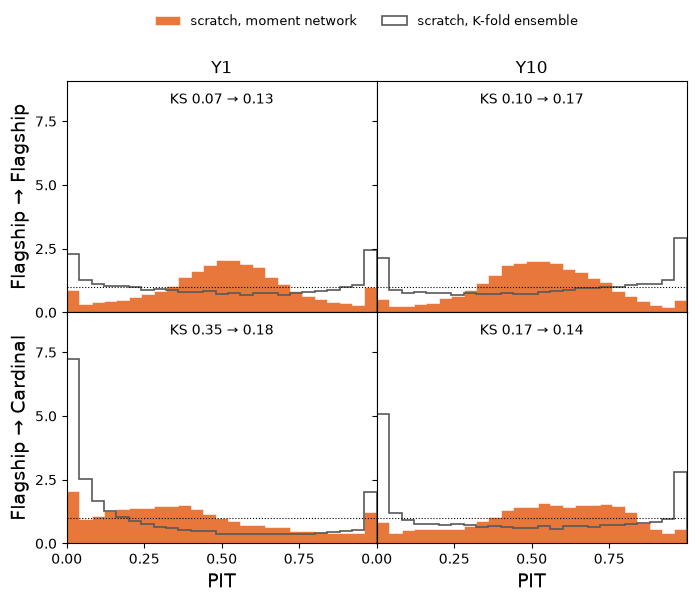

In [9]:
from matplotlib.ticker import MaxNLocator

pit_bins = np.linspace(0, 1, 26)
top = 0
fig, axes = plt.subplots(2, 2, figsize=(8, 6), sharex=True, sharey=True, gridspec_kw=dict(hspace=0, wspace=0))
for row, test_sim in enumerate(TEST_SIMS):
    for col, scenario in enumerate(SCENARIOS):
        ax = axes[row, col]
        c = (test_sim, scenario)
        heights, _, _ = ax.hist(pits[(NEW_LABEL, *c)], pit_bins, density=True, color=RUN_COLORS[NEW_LABEL],
                histtype="stepfilled", alpha=0.8, ec="white", lw=0.5, label=NEW_LABEL)
        base_heights, _, _ = ax.hist(pits[(BASELINE_LABEL, *c)], pit_bins, density=True, color=RUN_COLORS[BASELINE_LABEL],
                histtype="step", lw=1.2, label=BASELINE_LABEL)
        ax.axhline(1, color="k", lw=0.8, ls=":")
        ks_base, ks_new = results[(BASELINE_LABEL, *c)]["ks"], results[(NEW_LABEL, *c)]["ks"]
        ax.text(0.5, 0.95, f"KS {ks_base:.2f} → {ks_new:.2f}", transform=ax.transAxes, ha="center", va="top", fontsize=10,
                bbox=dict(fc="white", ec="none", alpha=0.8, pad=1))
        top = max(top, heights.max(), base_heights.max())
        if row == 0:
            ax.set_title(DEPTH_LABELS[scenario], fontsize=12)
        if col == 0:
            ax.set_ylabel(transfer_label(test_sim))
        if row == len(TEST_SIMS) - 1:
            ax.set_xlabel("PIT")
fig.legend(*axes[0, 0].get_legend_handles_labels(), fontsize=9, frameon=False, loc="lower center", ncol=2,
           bbox_to_anchor=(0.5, 0.95))
# with no gaps, keep the ticks off the panel edges so labels of neighbouring panels do not touch
axes[0, 0].set_xlim(0, 1)
axes[0, 0].set_ylim(0, 1.25 * top)  # headroom for the KS labels
axes[0, 0].set_xticks([0, 0.25, 0.5, 0.75])
axes[0, 0].yaxis.set_major_locator(MaxNLocator(nbins=4, prune="upper"))
save(fig, "pit")
plt.show()

### Point estimates

`zmode` against the reference redshift on the held-out set (log-density 2D histogram), the baseline (grey) next to the run at each depth. The dashed lines mark |Δz|/(1+z) = 0.2, the outlier threshold.

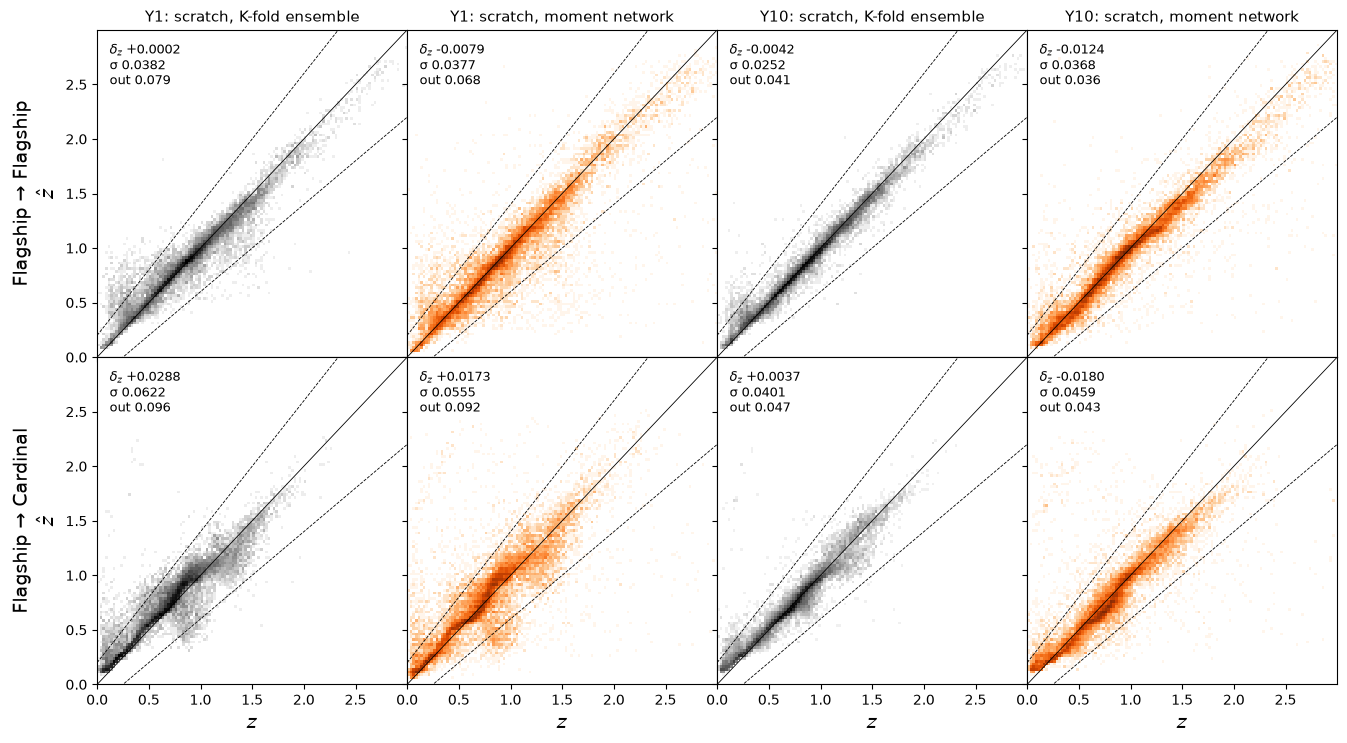

In [10]:
from matplotlib.colors import LogNorm

zb = np.linspace(0, 3, 121)
# columns: each depth, the baseline then the run
COLUMNS = [(scenario, model) for scenario in SCENARIOS for model in RUNS]
fig, axes = plt.subplots(len(TEST_SIMS), len(COLUMNS), figsize=(4 * len(COLUMNS), 4 * len(TEST_SIMS) + 0.5), sharex=True,
                         sharey=True, gridspec_kw=dict(hspace=0, wspace=0))
for row, test_sim in enumerate(TEST_SIMS):
    for col, (scenario, model) in enumerate(COLUMNS):
        ax = axes[row, col]
        key = (model, test_sim, scenario)
        h = heldout[key]
        ax.hist2d(h["z_ref"], h["zmode"], bins=[zb, zb], cmap=RUN_CMAPS[model], norm=LogNorm(), rasterized=True)
        ax.plot(zb, zb, color="k", lw=0.6)
        for sgn in (-1, 1):
            ax.plot(zb, zb + sgn * 0.2 * (1 + zb), color="k", lw=0.6, ls="--")
        v = table.loc[key]
        ax.text(0.04, 0.96, f"$\\delta_z$ {v['mean']:+.4f}\nσ {v['std']:.4f}\nout {v['abs_outlier_rate']:.3f}",
                transform=ax.transAxes, va="top", fontsize=9)
        if row == 0:
            ax.set_title(f"{DEPTH_LABELS[scenario]}: {model}", fontsize=11)
        if col == 0:
            ax.set_ylabel(f"{transfer_label(test_sim)}\n$\\hat{{z}}$")
        if row == len(TEST_SIMS) - 1:
            ax.set_xlabel("$z$")
axes[0, 0].set_xlim(0, 3)
axes[0, 0].set_ylim(0, 3)
# ticks stop short of 3 so labels of neighbouring panels do not touch
axes[0, 0].set_xticks(np.arange(0, 3, 0.5))
axes[0, 0].set_yticks(np.arange(0, 3, 0.5))
save(fig, "zphot_vs_zref")
plt.show()

### n(z)

The predicted n(z) of each held-out set against its reference redshifts, for both runs: the baseline as open grey circles, the run as filled points. One redshift is drawn from every object's p(z) and the draws are histogrammed. Repeating this `N_NZ_DRAWS` times gives the predicted n(z) in each bin (points: the mean over the draws, i.e. the stacked p(z)) and its uncertainty (error bars: the standard deviation over the draws). If the p(z)s are calibrated, the histogram of the reference redshifts (black) is one more such draw and should agree with the points within the error bars. The grey shadow is the n(z) of the Flagship training split the models were trained on: on Flagship it matches the held-out histogram, on Cardinal it shows how far Cardinal's redshift distribution is from what the models learned.

The table compares the two distributions, predicted minus reference: `Δ<z>` is the change in mean redshift and `Δσ_z` the change in width (standard deviation), both averaged over the draws. `KS` is the two-sample Kolmogorov-Smirnov statistic between the reference redshifts and all the draws pooled, i.e. the stacked p(z).

In [11]:
from matplotlib.ticker import MaxNLocator
from scipy.stats import ks_2samp

NZ_BINS = np.linspace(0, 3, 61)
NZ_CENTRES = 0.5 * (NZ_BINS[1:] + NZ_BINS[:-1])
N_NZ_DRAWS = 1_000
nz_rng = np.random.default_rng(NOISE_SEED)


def nz_hist(z):
    # n(z) normalised over all objects, so draws outside NZ_BINS (e.g. z < 0) lower it rather than being dropped
    return np.histogram(z, NZ_BINS)[0] / (len(z) * np.diff(NZ_BINS))


# the 80% of the training file each model was trained on, per depth
nz_train = {}
for scenario in SCENARIOS:
    train = znn.read_catalog(path("training", TASKSET, TRAIN_SIM, scenario))
    idx_train, _ = train_test_split(np.arange(len(train)), test_size=VAL_FRAC, random_state=SEED)
    nz_train[scenario] = nz_hist(reference_redshifts(train)[idx_train])

# predicted n(z) and its metrics by (run, test sim, depth); the reference n(z) by (test sim, depth), the same for both
nz_pred, nz_true, nz_metrics = {}, {}, {}
for key, h in heldout.items():
    z_draws = h["pz"].rvs(size=N_NZ_DRAWS, random_state=nz_rng)  # (objects, draws)
    nz_pred[key] = np.stack([nz_hist(zd) for zd in z_draws.T])
    nz_true[key[1:]] = nz_hist(h["z_ref"])
    nz_metrics[key] = {
        "Δ<z>": z_draws.mean(axis=0).mean() - h["z_ref"].mean(),
        "Δσ_z": z_draws.std(axis=0).mean() - h["z_ref"].std(),
        "KS": ks_2samp(h["z_ref"], z_draws.ravel()).statistic,
    }

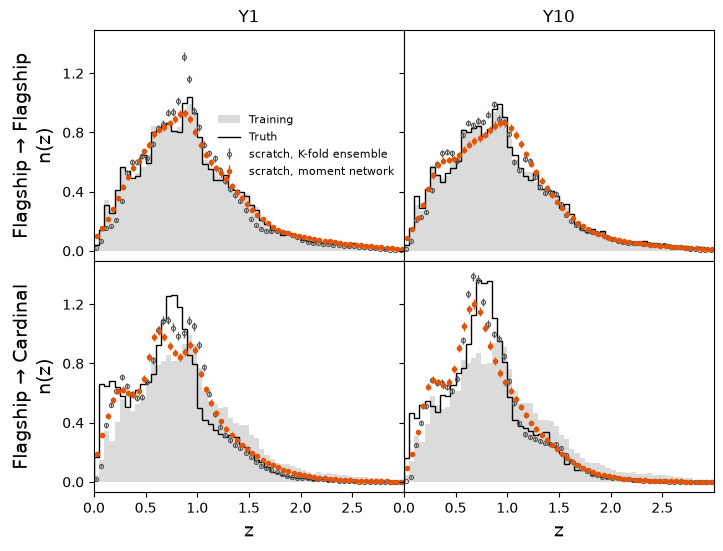

\begin{table}[htbp]
\caption{Predicted against held-out n(z) of the task set 3 models trained on Flagship, on Flagship and on Cardinal: scratch, moment network against scratch, K-fold ensemble. Change in mean redshift $\Delta\langle z \rangle$ and in width $\Delta\sigma_z$ (predicted minus reference), and the two-sample Kolmogorov--Smirnov statistic between the reference redshifts and redshifts drawn from the p(z)s.}
\label{tab:nz_metrics}
\begin{tabular}{lllrrr}
\toprule
 &  &  & $\Delta\langle z \rangle$ & $\Delta\sigma_z$ & KS \\
Tested on & Depth & Model &  &  &  \\
\midrule
\multirow[t]{4}{*}{Flagship} & \multirow[t]{2}{*}{Y1} & scratch, K-fold ensemble & -0.0137 & -0.0756 & 0.0398 \\
 &  & scratch, moment network & -0.0046 & -0.0240 & 0.0135 \\
 & \multirow[t]{2}{*}{Y10} & scratch, K-fold ensemble & -0.0112 & -0.0497 & 0.0326 \\
 &  & scratch, moment network & -0.0139 & -0.0394 & 0.0215 \\
\midrule
\multirow[t]{4}{*}{Cardinal} & \multirow[t]{2}{*}{Y1} & scratch, K-fold ensemble &

Δ<z>    Δσ_z      KS
test     scenario model                                           
flagship 1yr      scratch, K-fold ensemble -0.0137 -0.0756  0.0398
                  scratch, moment network  -0.0046 -0.0240  0.0135
         10yr     scratch, K-fold ensemble -0.0112 -0.0497  0.0326
                  scratch, moment network  -0.0139 -0.0394  0.0215
cardinal 1yr      scratch, K-fold ensemble  0.0426 -0.0434  0.0734
                  scratch, moment network   0.0462  0.0061  0.0675
         10yr     scratch, K-fold ensemble  0.0153 -0.0247  0.0461
                  scratch, moment network  -0.0019 -0.0042  0.0556

In [12]:
# the baseline's points are shifted left and the run's right of the bin centres, so their error bars do not overlap
NZ_SHIFT = {BASELINE_LABEL: -0.15 * np.diff(NZ_BINS)[0], NEW_LABEL: 0.15 * np.diff(NZ_BINS)[0]}
NZ_MARKER = {BASELINE_LABEL: dict(fmt="o", ms=3, mfc="none", mew=0.8), NEW_LABEL: dict(fmt="o", ms=3)}

fig, axes = plt.subplots(2, 2, figsize=(8, 6), sharex=True, sharey=True, gridspec_kw=dict(hspace=0, wspace=0))
for row, test_sim in enumerate(TEST_SIMS):
    for col, scenario in enumerate(SCENARIOS):
        ax = axes[row, col]
        c = (test_sim, scenario)
        ax.stairs(nz_train[scenario], NZ_BINS, fill=True, color=TRAIN_COLOR, alpha=0.35, lw=0, label="Training")
        ax.stairs(nz_true[c], NZ_BINS, color="k", lw=1.0, label="Truth")
        for model in RUNS:
            pred = nz_pred[(model, *c)]
            ax.errorbar(NZ_CENTRES + NZ_SHIFT[model], pred.mean(axis=0), pred.std(axis=0), lw=1, capsize=0,
                        color=RUN_COLORS[model], label=model, **NZ_MARKER[model])
        if row == 0:
            ax.set_title(DEPTH_LABELS[scenario], fontsize=12)
        if col == 0:
            ax.set_ylabel(f"{transfer_label(test_sim)}\nn(z)")
        if row == len(TEST_SIMS) - 1:
            ax.set_xlabel("z")
axes[0, 0].legend(fontsize=8, frameon=False, loc="center right")
# with no gaps, keep the ticks off the panel edges so labels of neighbouring panels do not touch
axes[0, 0].set_xlim(0, 3)
axes[0, 0].set_xticks(np.arange(0, 3, 0.5))
axes[0, 0].yaxis.set_major_locator(MaxNLocator(nbins=4, prune="upper"))
save(fig, "nz_heldout")
plt.show()

# the two runs in adjacent rows, per evaluation
nz_table = pd.DataFrame.from_dict(nz_metrics, orient="index")
nz_table.index.names = table.index.names
nz_table = nz_table.reorder_levels(["test", "scenario", "model"]).loc[[(*c, model) for c in EVALS for model in RUNS]]
save_latex(
    nz_table,
    "nz_metrics",
    {"Δ<z>": r"$\Delta\langle z \rangle$", "Δσ_z": r"$\Delta\sigma_z$", "KS": r"KS"},
    rf"Predicted against held-out n(z) of the task set 3 models trained on Flagship, on Flagship and on Cardinal: {NEW_LABEL} against {BASELINE_LABEL}. Change in mean redshift $\Delta\langle z \rangle$ and in width $\Delta\sigma_z$ "
    r"(predicted minus reference), and the two-sample Kolmogorov--Smirnov statistic between the reference redshifts and "
    r"redshifts drawn from the p(z)s.",
)
nz_table.round(4)